# Lab 6: Fine-Tune with LoRA

The question I'm working on: if I only train a low-rank update on two projections per layer, how much of full fine-tuning do I keep, and how much memory do I actually save? I'm using SmolLM2-135M on the emotion task. Every comparison has to be controlled, and every claim I make has to come from a number in this notebook.

**Before running:** Runtime > Change runtime type > T4 GPU.

## Colab setup

In [11]:
!pip install -q -U transformers peft datasets

In [12]:
# Colab ships torchao 0.10, which the new peft refuses to load next to; this lab never uses torchao
!pip uninstall -y -q torchao

In [13]:
import os

# lab06_starter.py sits next to this notebook. On Colab, pick it in the upload box if it isn't there yet.
if not os.path.exists("lab06_starter.py"):
    from google.colab import files
    files.upload()
print("starter present:", os.path.exists("lab06_starter.py"))

starter present: True


### Does the starter run as given?

Before I change anything I want to know the environment works, so I run the starter once, unmodified. If it fails here, nothing I build later can be trusted.

In [14]:
!python lab06_starter.py

device: cuda
Loading weights: 100% 272/272 [00:00<00:00, 809.80it/s]
example prompt: 'Text: i may feel that way but the fact that stories created by adults that are meant for children contain messages that are not so innocent really makes me wonder who exactly is\nEmotion:' answer: ' joy'
zero-shot accuracy (chance 0.167): 0.35
Loading weights: 100% 272/272 [00:00<00:00, 415.03it/s]
LoRA r=8, 30 steps: accuracy 0.510, trainable 460,800 of 134,975,808, 0.32 s/step


The starter runs on the T4 as given. Zero-shot is 0.35 on its 100-example check and LoRA r=8 reaches 0.51 after 30 steps, so the environment works before I change anything.

In [15]:
import copy
import gc
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
import peft
import torch
import torch.nn as nn
import transformers
import datasets

import lab06_starter as S

print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__, "| datasets", datasets.__version__)
print("device:", S.DEVICE, "|", torch.cuda.get_device_name(0) if S.DEVICE == "cuda" else "no GPU")

STEPS = 120
BATCH_SIZE = 8
SEEDS = [0, 1, 2]
RANKS = [1, 4, 16]
N_TRAIN, N_TEST, N_VALIDATION = 600, 500, 300
os.makedirs("figures", exist_ok=True)
results = {"steps": STEPS, "batch_size": BATCH_SIZE, "device": torch.cuda.get_device_name(0) if S.DEVICE == "cuda" else "cpu"}

torch 2.14.1+cu130 | transformers 5.22.2 | peft 0.21.2 | datasets 5.1.0
device: cuda | Tesla T4


## Zero-shot baseline and answer-only loss

Any gain from fine-tuning is meaningless until I know where the model starts. I'm going to score the pretrained model on the test set with no training at all, then put that number next to two floors:

- **Chance:** 1/6, if it guessed uniformly.
- **Majority label:** always answering the most common emotion. The emotion data is imbalanced, so this floor is higher than chance, and a model that beats chance can still lose to it.

I'm also counting what the model predicts, because an accuracy above chance can hide a model that says the same word every time.

In [16]:
base_model, tokenizer = S.load_model()
train_examples, test_examples, label_ids = S.load_task("emotion", n_train=N_TRAIN, n_test=N_TEST, tokenizer=tokenizer)
label_words = S.TASKS["emotion"]["words"]

print("label tokens:", {word: tokenizer.decode([token_id]) for word, token_id in zip(label_words, label_ids)})
print("example prompt:", repr(tokenizer.decode(train_examples[0]["prompt_ids"])),
      "answer:", repr(tokenizer.decode([train_examples[0]["answer_id"]])))


@torch.no_grad()
def predict_labels(model, examples, batch_size=32):
    """Same scoring as S.evaluate, but returns the predicted label for every example."""
    model.eval()
    label_tensor = torch.tensor(label_ids, device=S.DEVICE)
    predictions = []
    for start in range(0, len(examples), batch_size):
        chunk = examples[start:start + batch_size]
        input_ids, attention_mask, prompt_lens = S.pad_batch(chunk, tokenizer.pad_token_id)
        logits = model(input_ids=input_ids.to(S.DEVICE), attention_mask=attention_mask.to(S.DEVICE)).logits
        last_prompt_scores = logits[torch.arange(len(chunk)), (prompt_lens - 1).to(S.DEVICE)]
        predictions += last_prompt_scores[:, label_tensor].argmax(dim=-1).tolist()
    return predictions


zero_shot_accuracy = S.evaluate(base_model, tokenizer, test_examples, label_ids)
zero_shot_predictions = predict_labels(base_model, test_examples)
test_label_counts = pd.Series([label_words[example["label"]] for example in test_examples]).value_counts()
zero_shot_counts = pd.Series([label_words[prediction] for prediction in zero_shot_predictions]).value_counts()
chance = 1 / len(label_ids)
majority_rate = test_label_counts.iloc[0] / len(test_examples)

print(f"zero-shot accuracy: {zero_shot_accuracy:.3f}")
print(f"chance: {chance:.3f} | always '{test_label_counts.index[0]}': {majority_rate:.3f}")
print(pd.DataFrame({"true labels": test_label_counts, "zero-shot predictions": zero_shot_counts}).fillna(0).astype(int))
results.update(zero_shot_accuracy=zero_shot_accuracy, chance=chance, majority_label=test_label_counts.index[0],
               majority_rate=float(majority_rate))

label tokens: {'sadness': ' sadness', 'joy': ' joy', 'love': ' love', 'anger': ' anger', 'fear': ' fear', 'surprise': ' surprise'}
example prompt: 'Text: i may feel that way but the fact that stories created by adults that are meant for children contain messages that are not so innocent really makes me wonder who exactly is\nEmotion:' answer: ' joy'
zero-shot accuracy: 0.326
chance: 0.167 | always 'joy': 0.330
          true labels  zero-shot predictions
anger              66                     88
fear               58                      5
joy               165                     32
love               39                    265
sadness           153                    110
surprise           19                      0


Zero-shot lands at 0.326. That's about twice chance (0.167), but it's level with always answering joy (0.330), so on its own the pretrained model has no usable skill here. The prediction counts show why:

- **Love:** it says love for 265 of 500 tweets, when only 39 are love.
- **Joy:** the most common label (165) gets only 32 predictions.
- **Surprise:** never predicted at all.

Most of what it gets right comes from sadness and anger. So every fine-tuned number below has to clear 0.33, not just 0.167.

### Scoring only the answer

The starter's loss scores every token in the prompt, but the test only ever looks at one thing: the label score at the last prompt position. I want the loss to train exactly that. I'll write `answer_only_labels` so only the answer token is scored. Then I'll prove it with assertions instead of trusting it:

- **One per row:** exactly one position is scored in every example.
- **No prompt:** no prompt token is scored.
- **Right token:** the scored token is the answer.

The mistake the brief warns about is scoring one position too early, and it runs without any error. So I'm also writing that broken version on purpose to make sure my checks catch it.

In [17]:
def answer_only_labels(input_ids, attention_mask, prompt_lens):
    """Score only the answer token. Everything else, prompt and padding, is -100."""
    labels = torch.full_like(input_ids, -100)
    rows = torch.arange(input_ids.shape[0])
    labels[rows, prompt_lens] = input_ids[rows, prompt_lens]
    return labels


def off_by_one_labels(input_ids, attention_mask, prompt_lens):
    """The silent mistake from the brief: scores the last prompt token instead of the answer."""
    labels = torch.full_like(input_ids, -100)
    rows = torch.arange(input_ids.shape[0])
    labels[rows, prompt_lens - 1] = input_ids[rows, prompt_lens - 1]
    return labels


def check_answer_only(labels_fn, batch):
    input_ids, attention_mask, prompt_lens = S.pad_batch(batch, tokenizer.pad_token_id)
    labels = labels_fn(input_ids, attention_mask, prompt_lens)
    scored_per_row = (labels != -100).sum(dim=1)
    assert torch.all(scored_per_row == 1), f"scored positions per row: {scored_per_row.tolist()}"
    for row, example in enumerate(batch):
        assert torch.all(labels[row, :prompt_lens[row]] == -100), f"row {row} scores a prompt token"
        assert labels[row, prompt_lens[row]].item() == example["answer_id"], f"row {row} does not score the answer"
    return labels


check_batch = train_examples[:8]
input_ids, attention_mask, prompt_lens = S.pad_batch(check_batch, tokenizer.pad_token_id)
print("prompt lengths in the check batch:", prompt_lens.tolist())

answer_labels = check_answer_only(answer_only_labels, check_batch)
print("answer_only_labels passed: one scored position per row, no prompt token scored")
print("scored tokens:", [tokenizer.decode([token_id]) for token_id in answer_labels[answer_labels != -100].tolist()])

try:
    check_answer_only(off_by_one_labels, check_batch)
except AssertionError as error:
    shifted_labels = off_by_one_labels(input_ids, attention_mask, prompt_lens)
    shifted_tokens = [tokenizer.decode([token_id]) for token_id in shifted_labels[shifted_labels != -100].tolist()]
    print("off-by-one version fails:", error, "| it scores", shifted_tokens[:3])

all_token_labels = S.all_tokens_labels(input_ids, attention_mask, prompt_lens)
print("starter's all_tokens_labels scores per row:", (all_token_labels != -100).sum(dim=1).tolist())

prompt lengths in the check batch: [38, 21, 27, 11, 14, 29, 38, 31]
answer_only_labels passed: one scored position per row, no prompt token scored
scored tokens: [' joy', ' joy', ' love', ' sadness', ' joy', ' joy', ' fear', ' joy']
off-by-one version fails: row 0 scores a prompt token | it scores [':', ':', ':']
starter's all_tokens_labels scores per row: [39, 22, 28, 12, 15, 30, 39, 32]


Every row scores exactly one token, and it's always a label word (joy, love, sadness, fear). The off-by-one version trips the prompt assertion on the first row, because it scores the `:` at the end of `Emotion:`. The starter's version scores 12 to 39 tokens per row, so in its loss the answer is one token among dozens.

The assertions show which position gets the label, but not that Hugging Face's internal shift lines it up with the position `S.evaluate` reads. To close that gap I'm working out the cross-entropy at the last prompt position myself and comparing it with the loss the model reports. If the two don't match, training and evaluation are looking at different positions.

In [18]:
with torch.no_grad():
    batch_ids, batch_mask = input_ids.to(S.DEVICE), attention_mask.to(S.DEVICE)
    model_output = base_model(input_ids=batch_ids, attention_mask=batch_mask, labels=answer_labels.to(S.DEVICE))
    last_prompt_logits = model_output.logits[torch.arange(len(check_batch)), (prompt_lens - 1).to(S.DEVICE)]
    answer_tokens = torch.tensor([example["answer_id"] for example in check_batch], device=S.DEVICE)
    manual_loss = nn.functional.cross_entropy(last_prompt_logits, answer_tokens)
print(f"HF loss {model_output.loss.item():.6f} | manual loss at last prompt position {manual_loss.item():.6f}")
assert torch.allclose(model_output.loss, manual_loss, atol=1e-5)

HF loss 6.229302 | manual loss at last prompt position 6.229302


Both losses come out at 6.229302. After its shift, Hugging Face predicts my label from the last prompt position, the same position `S.evaluate` reads, so training and evaluation are looking at the same place.

**What the starter's all-token loss actually trains:** it puts most of the gradient into predicting the "Text: … Emotion:" template and the tweet itself, which is language modelling on tweets. That isn't the skill I'm measuring, because the test never checks how well the model predicts the prompt, only which of six label tokens it scores highest at the end.

## LoRA from scratch, verified

Now I need my own LoRA layer: a frozen `nn.Linear` plus `(alpha / r) B A`, with A small and random and B at zero. A LoRA layer with a wrong scale or a transposed product still trains, and it still gives plausible accuracy. So I don't trust it until it has passed four checks:

- **Init:** it equals the original layer at the start.
- **Count:** its trainable parameters are `r * (in + out)`.
- **Merge:** folding `B A` into the weight gives the same output.
- **peft:** it matches peft once both hold the same A and B.

I'm drawing A from the same uniform range peft uses (bound `1/sqrt(in_features)`), so the comparison is like for like.

In [19]:
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base = base
        for parameter in self.base.parameters():
            parameter.requires_grad_(False)
        self.r = r
        self.alpha = alpha
        self.scaling = alpha / r
        base_weight = base.weight
        bound = 1 / base.in_features ** 0.5
        self.lora_A = nn.Parameter(
            (torch.rand(r, base.in_features, device=base_weight.device, dtype=base_weight.dtype) * 2 - 1) * bound)
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r, device=base_weight.device, dtype=base_weight.dtype))

    def forward(self, x):
        return self.base(x) + (x @ self.lora_A.T @ self.lora_B.T) * self.scaling

    def merged(self):
        """A plain nn.Linear holding W + (alpha / r) B A."""
        merged_layer = nn.Linear(self.base.in_features, self.base.out_features, bias=self.base.bias is not None,
                                 device=self.base.weight.device, dtype=self.base.weight.dtype)
        with torch.no_grad():
            merged_layer.weight.copy_(self.base.weight + self.scaling * self.lora_B @ self.lora_A)
            if self.base.bias is not None:
                merged_layer.bias.copy_(self.base.bias)
        return merged_layer


def inject_lora(model, r, alpha, target_modules=("q_proj", "v_proj")):
    """Freeze every weight, then swap each target nn.Linear for a LoRALinear. Returns the wrapped layers."""
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    targets = [(name, module) for name, module in model.named_modules()
               if name.split(".")[-1] in target_modules and isinstance(module, nn.Linear)]
    wrapped_layers = {}
    for name, module in targets:
        parent_name, child_name = name.rsplit(".", 1)
        lora_layer = LoRALinear(module, r, alpha)
        setattr(model.get_submodule(parent_name), child_name, lora_layer)
        wrapped_layers[name] = lora_layer
    return wrapped_layers

### Checking one layer before trusting the whole model

I'm starting small, on a copy of the first q_proj. A bug is much easier to see in one layer than in 60. The merge check only means something once B is nonzero, so I'm filling B with random values before it.

In [20]:
torch.manual_seed(0)
check_rank, check_alpha = 4, 8
q_proj_copy = copy.deepcopy(base_model.model.layers[0].self_attn.q_proj)
lora_layer = LoRALinear(q_proj_copy, check_rank, check_alpha)
sample_input = torch.randn(3, 11, q_proj_copy.in_features, device=S.DEVICE)

print("identical to the wrapped layer at init:", torch.equal(lora_layer(sample_input), q_proj_copy(sample_input)))
trainable_count = sum(parameter.numel() for parameter in lora_layer.parameters() if parameter.requires_grad)
expected_count = check_rank * (q_proj_copy.in_features + q_proj_copy.out_features)
print(f"trainable {trainable_count} | r * (in + out) = {check_rank} * ({q_proj_copy.in_features} + {q_proj_copy.out_features}) = {expected_count}")
assert trainable_count == expected_count

with torch.no_grad():
    lora_layer.lora_B.normal_(0, 0.02)
two_path_output = lora_layer(sample_input)
merged_output = lora_layer.merged()(sample_input)
print(f"merged vs two-path, B nonzero: max diff {(merged_output - two_path_output).abs().max().item():.2e}")
assert torch.allclose(merged_output, two_path_output, atol=1e-4)
print(f"and the update is no longer zero: max |two-path - base| {(two_path_output - q_proj_copy(sample_input)).abs().max().item():.2e}")

identical to the wrapped layer at init: True
trainable 4608 | r * (in + out) = 4 * (576 + 576) = 4608
merged vs two-path, B nonzero: max diff 1.62e-05
and the update is no longer zero: max |two-path - base| 3.11e-01


At init the layer is identical to q_proj, and the trainable count is 4 × (576 + 576) = 4,608. Once B is filled in, the merged layer matches the two-path layer to 1.6e-05, which is float32 rounding. The update itself moves the output by 0.31, so the match isn't just two copies of a zero update.

The comparison with peft is the check that catches a wrong scale. I'm copying my A and B into a peft layer and comparing the outputs. Then I'm deliberately scaling by `alpha` instead of `alpha / r`, to see that the peft check would have caught that mistake.

In [21]:
from peft import LoraConfig, get_peft_model


class OneLayer(nn.Module):
    def __init__(self, layer):
        super().__init__()
        self.q_proj = layer

    def forward(self, x):
        return self.q_proj(x)


peft_holder = get_peft_model(OneLayer(copy.deepcopy(base_model.model.layers[0].self_attn.q_proj)),
                             LoraConfig(r=check_rank, lora_alpha=check_alpha, target_modules=["q_proj"],
                                        lora_dropout=0.0, bias="none"))
peft_layer = peft_holder.base_model.model.q_proj
with torch.no_grad():
    peft_layer.lora_A["default"].weight.copy_(lora_layer.lora_A)
    peft_layer.lora_B["default"].weight.copy_(lora_layer.lora_B)
peft_output = peft_layer(sample_input)
print(f"mine vs peft, same A and B: max diff {(two_path_output - peft_output).abs().max().item():.2e} | peft scaling {peft_layer.scaling['default']}")
assert torch.allclose(two_path_output, peft_output, atol=1e-4)

wrong_scaling_output = q_proj_copy(sample_input) + (sample_input @ lora_layer.lora_A.T @ lora_layer.lora_B.T) * check_alpha
print(f"scaled by alpha instead of alpha/r: max diff to peft {(wrong_scaling_output - peft_output).abs().max().item():.2e}")

mine vs peft, same A and B: max diff 0.00e+00 | peft scaling 2.0
scaled by alpha instead of alpha/r: max diff to peft 9.34e-01


With the same A and B, mine and peft agree exactly (0.00e+00), and peft's scaling is 2.0 = 8 / 4. Scaling by alpha instead of alpha / r is off by 0.93, so this check would have caught the mistake the brief warns about.

### Does it hold across the whole model?

One layer passing doesn't prove `inject_lora` found the right modules or wired them in properly. I'm going to inject my LoRA into a full copy of the model and check two things:

- **Init:** the logits are identical to the pretrained model's at the start. This is the brief's "starts identical" requirement.
- **peft:** after B is made nonzero and the same A and B are copied into a peft model, the logits still match.

In [22]:
torch.manual_seed(0)
my_lora_model = copy.deepcopy(base_model)
my_wrapped_layers = inject_lora(my_lora_model, r=check_rank, alpha=check_alpha)
batch_ids, batch_mask = input_ids.to(S.DEVICE), attention_mask.to(S.DEVICE)
with torch.no_grad():
    base_logits = base_model(input_ids=batch_ids, attention_mask=batch_mask).logits
    my_logits = my_lora_model(input_ids=batch_ids, attention_mask=batch_mask).logits
print(f"{len(my_wrapped_layers)} layers wrapped | adapted model at init vs pretrained: identical = {torch.equal(base_logits, my_logits)}")

with torch.no_grad():
    for wrapped_layer in my_wrapped_layers.values():
        wrapped_layer.lora_B.normal_(0, 0.02)
peft_model = S.apply_lora(copy.deepcopy(base_model), r=check_rank, alpha=check_alpha)
with torch.no_grad():
    for module_name, wrapped_layer in my_wrapped_layers.items():
        peft_module = peft_model.get_submodule("base_model.model." + module_name)
        peft_module.lora_A["default"].weight.copy_(wrapped_layer.lora_A)
        peft_module.lora_B["default"].weight.copy_(wrapped_layer.lora_B)
    my_logits = my_lora_model(input_ids=batch_ids, attention_mask=batch_mask).logits
    peft_logits = peft_model(input_ids=batch_ids, attention_mask=batch_mask).logits
print(f"whole model, mine vs peft with B nonzero: max logit diff {(my_logits - peft_logits).abs().max().item():.2e}")
assert torch.allclose(my_logits, peft_logits, atol=1e-3)

60 layers wrapped | adapted model at init vs pretrained: identical = True
whole model, mine vs peft with B nonzero: max logit diff 0.00e+00


All 60 targets are wrapped (q_proj and v_proj in 30 layers). At init the adapted model's logits are identical to the pretrained model's. With B nonzero, my model and peft's give the same logits to the last bit.

### How many parameters am I actually training?

Before any training I want the trainable count at ranks 1, 4 and 16, as a share of the whole model. I'll compare each count with `r * (in + out)` summed over every wrapped layer. q_proj and v_proj have different output sizes in this model, so the formula has to come from each layer's real shape, not from one number reused.

In [23]:
parameter_rows = []
for rank in RANKS:
    counting_model = copy.deepcopy(base_model)
    counted_layers = inject_lora(counting_model, r=rank, alpha=2 * rank)
    trainable_count, total_count = S.count_params(counting_model)
    formula_count = sum(rank * (layer.base.in_features + layer.base.out_features) for layer in counted_layers.values())
    assert trainable_count == formula_count
    parameter_rows.append(dict(rank=rank, wrapped_layers=len(counted_layers), trainable=trainable_count,
                               formula_sum=formula_count, total=total_count,
                               percent_of_model=100 * trainable_count / total_count))
    del counting_model
parameter_table = pd.DataFrame(parameter_rows)
first_attention = base_model.model.layers[0].self_attn
print(f"q_proj in/out ({first_attention.q_proj.in_features}, {first_attention.q_proj.out_features}), "
      f"v_proj in/out ({first_attention.v_proj.in_features}, {first_attention.v_proj.out_features}), "
      f"layers {len(base_model.model.layers)}")
print(parameter_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
results["lora_parameters"] = parameter_rows

del my_lora_model, peft_model, peft_holder, base_model
gc.collect()
torch.cuda.empty_cache()

q_proj in/out (576, 576), v_proj in/out (576, 192), layers 30
 rank  wrapped_layers  trainable  formula_sum     total  percent_of_model
    1              60      57600        57600 134572608            0.0428
    4              60     230400       230400 134745408            0.1710
   16              60     921600       921600 135436608            0.6805


The counts match the formula at every rank: 57,600, 230,400 and 921,600, which is 0.04%, 0.17% and 0.68% of the model. v_proj only outputs 192 because the model shares keys and values across heads (grouped-query attention), so each layer adds r × (1152 + 768) = 1,920r, times 30 layers.

## Rank sweep against full fine-tuning

### Picking learning rates without touching the test set

Full fine-tuning and LoRA need very different learning rates. If I just reuse the LoRA rate for full fine-tuning, full fine-tuning probably blows up, and LoRA looks better than it really is. I can't pick rates by looking at test accuracy either, because then the test set stops being a test.

My plan is to tune on 300 examples from the dataset's own validation split, seed 0 only:

- **Full fine-tuning:** its own grid of rates.
- **LoRA:** tuned at rank 4, and that rate is reused for ranks 1 and 16. With alpha = 2r the update is scaled by 2 at every rank, so one rate is a fair starting point, but it is a shortcut and I'll count it as a limit.

I'm also checking that the training sample hasn't changed and that no validation prompt also appears in the test set.

In [24]:
search_train_examples, validation_examples, _ = S.load_task("emotion", n_train=N_TRAIN, n_test=N_VALIDATION,
                                                            tokenizer=tokenizer, eval_split="validation")
assert [example["prompt_ids"] for example in search_train_examples] == [example["prompt_ids"] for example in train_examples], \
    "training sample changed"
test_prompts = {tuple(example["prompt_ids"]) for example in test_examples}
print("validation prompts that also appear in test:",
      sum(tuple(example["prompt_ids"]) in test_prompts for example in validation_examples))


def run_experiment(method, seed, learning_rate, eval_examples, rank=None, labels_fn=answer_only_labels):
    """One run on a freshly loaded model. Same data, steps, batch size and optimizer for every method."""
    torch.manual_seed(seed)
    model, _ = S.load_model()
    if method == "lora":
        inject_lora(model, r=rank, alpha=2 * rank)
    run_info = S.train(model, tokenizer, train_examples, steps=STEPS, lr=learning_rate, batch_size=BATCH_SIZE,
                       seed=seed, labels_fn=labels_fn)
    run_info["accuracy"] = S.evaluate(model, tokenizer, eval_examples, label_ids)
    run_info.update(method=method if method == "full" else f"lora r={rank}", rank=rank, seed=seed,
                    learning_rate=learning_rate, loss=labels_fn.__name__)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    print(f"  {run_info['method']:<10} seed {seed} lr {learning_rate:<7g} {run_info['loss']:<20} acc {run_info['accuracy']:.3f} "
          f"loss {run_info['first_loss']:.3f} -> {run_info['last_loss']:.3f} ({run_info['seconds']:.0f}s)")
    return run_info


search_grid = {"full": [1e-5, 3e-5, 1e-4, 3e-4], "lora": [1e-4, 3e-4, 1e-3, 3e-3]}
search_runs = []
for method, learning_rates in search_grid.items():
    for learning_rate in learning_rates:
        search_runs.append(run_experiment(method, 0, learning_rate, validation_examples,
                                          rank=4 if method == "lora" else None))

search_table = pd.DataFrame(search_runs)[["method", "learning_rate", "accuracy", "first_loss", "last_loss"]]
print(search_table.rename(columns={"accuracy": "validation_accuracy"}).to_string(index=False))
chosen_lr = {"full": float(search_table[search_table.method == "full"].sort_values("accuracy").iloc[-1].learning_rate),
             "lora": float(search_table[search_table.method == "lora r=4"].sort_values("accuracy").iloc[-1].learning_rate)}
print("chosen learning rates:", chosen_lr)
results["lr_search"] = search_table.to_dict("records")
results["chosen_lr"] = chosen_lr

validation prompts that also appear in test: 0


  full       seed 0 lr 1e-05   answer_only_labels   acc 0.717 loss 5.269 -> 0.530 (34s)


  full       seed 0 lr 3e-05   answer_only_labels   acc 0.750 loss 4.515 -> 0.423 (21s)


  full       seed 0 lr 0.0001  answer_only_labels   acc 0.803 loss 3.556 -> 0.313 (23s)


  full       seed 0 lr 0.0003  answer_only_labels   acc 0.740 loss 2.872 -> 0.979 (25s)


  lora r=4   seed 0 lr 0.0001  answer_only_labels   acc 0.547 loss 5.791 -> 1.209 (16s)


  lora r=4   seed 0 lr 0.0003  answer_only_labels   acc 0.640 loss 5.758 -> 0.746 (15s)


  lora r=4   seed 0 lr 0.001   answer_only_labels   acc 0.700 loss 5.628 -> 0.589 (16s)


  lora r=4   seed 0 lr 0.003   answer_only_labels   acc 0.767 loss 5.183 -> 0.481 (16s)
  method  learning_rate  validation_accuracy  first_loss  last_loss
    full        0.00001             0.716667    5.268607   0.529961
    full        0.00003             0.750000    4.514587   0.422761
    full        0.00010             0.803333    3.556021   0.312577
    full        0.00030             0.740000    2.872226   0.978602
lora r=4        0.00010             0.546667    5.790879   1.208865
lora r=4        0.00030             0.640000    5.757687   0.746405
lora r=4        0.00100             0.700000    5.628346   0.588589
lora r=4        0.00300             0.766667    5.182702   0.481441
chosen learning rates: {'full': 0.0001, 'lora': 0.003}


The validation search settles both rates, and they're far apart:

- **Full:** best at 1e-4 (0.803). At 3e-4 it falls back to 0.740 and the final loss climbs to 0.98, so the best rate sits inside the grid.
- **LoRA (rank 4):** keeps improving all the way to 3e-3 (0.767), the top of its grid, so its true best could be higher still.
- **Gap:** the LoRA rate is 30× the full rate, which is exactly why the brief says not to reuse one for the other.

I only tuned LoRA at rank 4, and the sweep below shows that was a mistake for rank 16.

### The sweep

This is where my prediction gets tested. It's written in the README and was committed before this cell ran. Full fine-tuning and LoRA at ranks 1, 4 and 16 each get seeds 0, 1 and 2. Everything else stays the same: answer-only loss, training examples, test set, step count and batch size. The learning rate is the only other thing that differs between methods, and I'm reporting it next to the accuracy.

In [25]:
sweep_runs = []
sweep_start = time.time()
for seed in SEEDS:
    sweep_runs.append(run_experiment("full", seed, chosen_lr["full"], test_examples))
    for rank in RANKS:
        sweep_runs.append(run_experiment("lora", seed, chosen_lr["lora"], test_examples, rank=rank))
print(f"sweep took {(time.time() - sweep_start) / 60:.1f} min")
results["sweep"] = sweep_runs

  full       seed 0 lr 0.0001  answer_only_labels   acc 0.812 loss 3.556 -> 0.313 (21s)


  lora r=1   seed 0 lr 0.003   answer_only_labels   acc 0.762 loss 5.652 -> 0.638 (16s)


  lora r=4   seed 0 lr 0.003   answer_only_labels   acc 0.776 loss 5.183 -> 0.481 (16s)


  lora r=16  seed 0 lr 0.003   answer_only_labels   acc 0.476 loss 4.303 -> 0.866 (16s)


  full       seed 1 lr 0.0001  answer_only_labels   acc 0.794 loss 3.474 -> 0.483 (20s)


  lora r=1   seed 1 lr 0.003   answer_only_labels   acc 0.760 loss 5.656 -> 0.524 (16s)


... (2 outputs left out)

  full       seed 2 lr 0.0001  answer_only_labels   acc 0.790 loss 3.522 -> 0.383 (20s)


  lora r=1   seed 2 lr 0.003   answer_only_labels   acc 0.764 loss 5.376 -> 0.527 (15s)


  lora r=4   seed 2 lr 0.003   answer_only_labels   acc 0.772 loss 4.979 -> 0.509 (16s)


  lora r=16  seed 2 lr 0.003   answer_only_labels   acc 0.714 loss 4.137 -> 0.702 (16s)
sweep took 4.1 min


A mean on its own can hide a seed that failed, so I'm putting every seed in the table. I'm reading each method against zero-shot and chance, and keeping the final training loss alongside to see whether a weak result means the method didn't fit the data or fit it and didn't generalise.

In [26]:
method_order = ["full"] + [f"lora r={rank}" for rank in RANKS]
seed_columns = [f"seed {seed}" for seed in SEEDS]
sweep_frame = pd.DataFrame(sweep_runs)
accuracy_table = sweep_frame.pivot(index="method", columns="seed", values="accuracy").loc[method_order]
accuracy_table.columns = seed_columns
accuracy_table["mean"] = accuracy_table[seed_columns].mean(axis=1)
accuracy_table["std"] = accuracy_table[seed_columns].std(axis=1)
accuracy_table["mean - zero-shot"] = accuracy_table["mean"] - zero_shot_accuracy
accuracy_table["mean - chance"] = accuracy_table["mean"] - chance
accuracy_table["learning rate"] = [f"{chosen_lr['full']:g}"] + [f"{chosen_lr['lora']:g}"] * len(RANKS)
accuracy_table["trainable"] = sweep_frame.groupby("method").trainable.first().loc[method_order]
accuracy_table["s/step"] = sweep_frame.groupby("method").seconds_per_step.mean().loc[method_order]
print(f"zero-shot {zero_shot_accuracy:.3f} | chance {chance:.3f} | majority '{results['majority_label']}' {majority_rate:.3f}")
print(accuracy_table.to_string(float_format=lambda value: f"{value:.3f}"))
print()
final_loss_table = sweep_frame.pivot(index="method", columns="seed", values="last_loss").loc[method_order]
final_loss_table.columns = [f"final loss seed {seed}" for seed in SEEDS]
print(final_loss_table.to_string(float_format=lambda value: f"{value:.3f}"))

zero-shot 0.326 | chance 0.167 | majority 'joy' 0.330
           seed 0  seed 1  seed 2  mean   std  mean - zero-shot  mean - chance learning rate  trainable  s/step
method                                                                                                         
full        0.812   0.794   0.790 0.799 0.012             0.473          0.632        0.0001  134515008   0.171
lora r=1    0.762   0.760   0.764 0.762 0.002             0.436          0.595         0.003      57600   0.131
lora r=4    0.776   0.712   0.772 0.753 0.036             0.427          0.587         0.003     230400   0.132
lora r=16   0.476   0.664   0.714 0.618 0.125             0.292          0.451         0.003     921600   0.131

           final loss seed 0  final loss seed 1  final loss seed 2
method                                                            
full                   0.313              0.483              0.383
lora r=1               0.638              0.524              0.527
lora 

I ran all twelve runs, and the table shows:

- **Full:** 0.790 to 0.812, mean 0.799, 0.47 above zero-shot and the best of the four.
- **Rank 1:** 0.760 to 0.764, mean 0.762. That's 3.7 points behind full while training 0.04% of the parameters, and it's the most consistent across seeds.
- **Rank 4:** mean 0.753, but seed 1 dropped to 0.712.
- **Rank 16:** seed 0 fell to 0.476 and the mean is 0.618. Its final loss is the highest of any run (0.65 to 0.87), so it isn't overfitting. It's failing to fit.

My prediction said rank 16 would land within 2 points of full; it's 18 points behind. My prediction that rank 1 wouldn't be clearly worse held. I think the rank 16 result comes from the shared learning rate, not the rank. alpha = 2r keeps the scale at 2, but Adam moves every entry of A and B by about the learning rate, so the size of B A grows with r. At 3e-3, a rate already at the edge for rank 4, rank 16 takes much bigger steps. I didn't run a test that separates the two, so it stays a hypothesis.

LoRA steps are only 23% faster (0.131 s against 0.171 s), because the forward and backward pass still run through every frozen layer.

### Does scoring the prompt help or hurt?

Earlier I argued the all-token loss trains the wrong skill. That was reasoning, not evidence, so now I'm testing it. I'm re-running rank 16 on the same three seeds with the starter's all-token loss, keeping everything else the same, including the learning rate. Whatever difference shows up comes from the loss alone.

In [27]:
all_token_runs = [run_experiment("lora", seed, chosen_lr["lora"], test_examples, rank=16, labels_fn=S.all_tokens_labels)
                  for seed in SEEDS]
results["all_token_r16"] = all_token_runs
loss_comparison = pd.DataFrame({
    "answer-only": [run["accuracy"] for run in sweep_runs if run["method"] == "lora r=16"],
    "all-token": [run["accuracy"] for run in all_token_runs]}, index=seed_columns)
loss_comparison["all-token - answer-only"] = loss_comparison["all-token"] - loss_comparison["answer-only"]
loss_comparison.loc["mean"] = loss_comparison.mean()
print(loss_comparison.to_string(float_format=lambda value: f"{value:.3f}"))

  lora r=16  seed 0 lr 0.003   all_tokens_labels    acc 0.712 loss 4.523 -> 2.683 (16s)


  lora r=16  seed 1 lr 0.003   all_tokens_labels    acc 0.672 loss 4.738 -> 2.791 (15s)


  lora r=16  seed 2 lr 0.003   all_tokens_labels    acc 0.704 loss 4.764 -> 2.735 (16s)
        answer-only  all-token  all-token - answer-only
seed 0        0.476      0.712                    0.236
seed 1        0.664      0.672                    0.008
seed 2        0.714      0.704                   -0.010
mean          0.618      0.696                    0.078


All-token loss scored higher on average (0.696 against 0.618), but almost all of that is seed 0, which went from 0.476 to 0.712. Seeds 1 and 2 moved by +0.008 and −0.010. With the loss averaged over 12 to 39 tokens, the answer token gets a small share of each step, which works like a lower learning rate on the classification. So I can't say scoring the prompt helped; more likely it stopped the too-high rate from breaking seed 0. Its final loss (2.7) is mostly prompt loss, so it can't be compared with the other runs'.

To see the whole sweep at once I'm plotting every seed as a dot, with the mean as a bar, against the zero-shot, majority and chance lines.

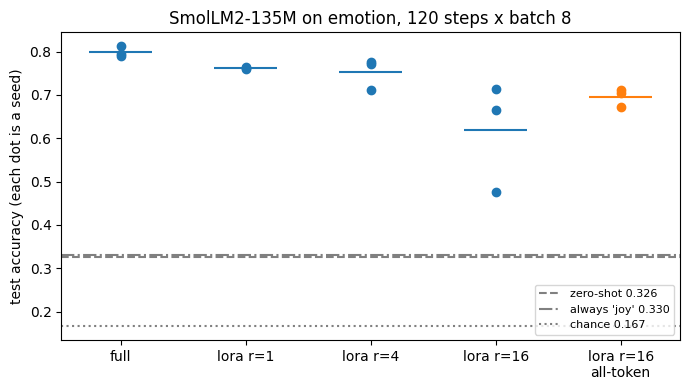

In [28]:
figure, axis = plt.subplots(figsize=(7, 4))
plot_labels = method_order + ["lora r=16\nall-token"]
for position, method in enumerate(method_order):
    seed_accuracies = sweep_frame[sweep_frame.method == method].accuracy
    axis.scatter([position] * len(seed_accuracies), seed_accuracies, color="tab:blue", zorder=3)
    axis.hlines(seed_accuracies.mean(), position - 0.25, position + 0.25, color="tab:blue")
all_token_accuracies = [run["accuracy"] for run in all_token_runs]
axis.scatter([len(method_order)] * len(all_token_accuracies), all_token_accuracies, color="tab:orange", zorder=3)
axis.hlines(sum(all_token_accuracies) / len(all_token_accuracies), len(method_order) - 0.25, len(method_order) + 0.25,
            color="tab:orange")
axis.axhline(zero_shot_accuracy, color="grey", linestyle="--", label=f"zero-shot {zero_shot_accuracy:.3f}")
axis.axhline(majority_rate, color="grey", linestyle="-.", label=f"always '{results['majority_label']}' {majority_rate:.3f}")
axis.axhline(chance, color="grey", linestyle=":", label=f"chance {chance:.3f}")
axis.set_xticks(range(len(plot_labels)), plot_labels)
axis.set_ylabel("test accuracy (each dot is a seed)")
axis.set_title(f"SmolLM2-135M on emotion, {STEPS} steps x batch {BATCH_SIZE}")
axis.legend(fontsize=8, loc="lower right")
figure.tight_layout()
figure.savefig("figures/accuracy_by_method.png", dpi=150)
plt.show()

The plot makes the rank 16 spread obvious. Its seeds span 0.24, against 0.06 or less for every other method, and its seed 0 (0.476) sits 0.19 below the next lowest run on the plot.

## Memory: predict, then measure

Unlike the accuracy claim, the memory saving can be worked out exactly ahead of time. So I'm writing my prediction down before I look at any measurement. It uses 4 bytes per weight, plus 12 more bytes per trainable parameter for its gradient and two Adam moments. I'm counting parameters from the model's config file rather than from the loaded model, so the prediction can't just copy the measurement back.

In [29]:
config = transformers.AutoConfig.from_pretrained(S.MODEL_NAME)
hidden_size = config.hidden_size
head_dim = hidden_size // config.num_attention_heads
kv_dim = config.num_key_value_heads * head_dim
params_per_layer = (hidden_size * hidden_size + 2 * hidden_size * kv_dim + hidden_size * hidden_size
                    + 3 * hidden_size * config.intermediate_size + 2 * hidden_size)
embedding_params = config.vocab_size * hidden_size
base_parameter_count = (embedding_params * (1 if config.tie_word_embeddings else 2)
                        + config.num_hidden_layers * params_per_layer + hidden_size)
print(f"hidden {hidden_size}, kv dim {kv_dim}, layers {config.num_hidden_layers}, vocab {config.vocab_size}, "
      f"tied embeddings {config.tie_word_embeddings} -> {base_parameter_count:,} parameters")

prediction_rows = []
for method in method_order:
    if method == "full":
        trainable_count, total_count = base_parameter_count, base_parameter_count
    else:
        rank = int(method.split("=")[1])
        trainable_count = config.num_hidden_layers * rank * ((hidden_size + hidden_size) + (hidden_size + kv_dim))
        total_count = base_parameter_count + trainable_count
    prediction_rows.append(dict(method=method, trainable=trainable_count, predicted_weights=4 * total_count,
                                predicted_grads=4 * trainable_count, predicted_adam=8 * trainable_count,
                                predicted_total=4 * total_count + 12 * trainable_count))
prediction_table = pd.DataFrame(prediction_rows).set_index("method")
print(prediction_table.to_string())
results["memory_prediction"] = prediction_table.reset_index().to_dict("records")

hidden 576, kv dim 192, layers 30, vocab 49152, tied embeddings True -> 134,515,008 parameters
           trainable  predicted_weights  predicted_grads  predicted_adam  predicted_total
method                                                                                   
full       134515008          538060032        538060032      1076120064       2152240128
lora r=1       57600          538290432           230400          460800        538981632
lora r=4      230400          538981632           921600         1843200        541746432
lora r=16     921600          541746432          3686400         7372800        552805632


From the config alone I predict 134,515,008 parameters; the embeddings are tied, so I count them once. Full fine-tuning should hold about 2.15 GB in weights, gradients and Adam state. LoRA should hold about 0.54 GB, almost all of it frozen weights.

Now I'm comparing the prediction with what the starter measured during the sweep. The weight, gradient and Adam byte counts should be the same on every seed, and I'm asserting that before using one seed's numbers. I'm also bringing in the peak GPU memory. My prediction leaves out activations, so I expect the peak to be higher, and how much higher is what I want to explain.

In [30]:
to_mb = lambda byte_count: byte_count / 2 ** 20
memory_columns = ["weight_bytes", "grad_bytes", "optimizer_bytes", "peak_cuda_bytes"]
seed_spread = sweep_frame.groupby("method")[memory_columns].agg(["min", "max"])
for column in ["weight_bytes", "grad_bytes", "optimizer_bytes"]:
    assert (seed_spread[column]["min"] == seed_spread[column]["max"]).all(), f"{column} differs across seeds"
measured = sweep_frame.groupby("method")[memory_columns].first().loc[method_order]
measured["measured_total"] = measured.weight_bytes + measured.grad_bytes + measured.optimizer_bytes

memory_table = pd.DataFrame({
    "weights pred MB": to_mb(prediction_table.predicted_weights), "weights meas MB": to_mb(measured.weight_bytes),
    "grads pred MB": to_mb(prediction_table.predicted_grads), "grads meas MB": to_mb(measured.grad_bytes),
    "adam pred MB": to_mb(prediction_table.predicted_adam), "adam meas MB": to_mb(measured.optimizer_bytes),
    "total pred MB": to_mb(prediction_table.predicted_total), "total meas MB": to_mb(measured.measured_total),
    "pred - meas bytes": prediction_table.predicted_total - measured.measured_total,
    "peak CUDA MB": to_mb(measured.peak_cuda_bytes),
    "peak / pred": measured.peak_cuda_bytes / prediction_table.predicted_total})
print(memory_table.to_string(float_format=lambda value: f"{value:.2f}"))
grads_and_adam = measured.grad_bytes + measured.optimizer_bytes
print(f"\nfull vs lora r=16, training state: {measured.measured_total['full'] / measured.measured_total['lora r=16']:.2f}x, "
      f"grads + adam: {grads_and_adam['full'] / grads_and_adam['lora r=16']:.0f}x")
results["memory_measured"] = measured.reset_index().to_dict("records")

           weights pred MB  weights meas MB  grads pred MB  grads meas MB  adam pred MB  adam meas MB  total pred MB  total meas MB  pred - meas bytes  peak CUDA MB  peak / pred
method                                                                                                                                                                           
full                513.13           513.13         513.13         513.13       1026.27       1026.27        2052.54        2052.54                  0       3164.98         1.54
lora r=1            513.35           513.35           0.22           0.22          0.44          0.44         514.01         514.01                  0       1494.09         2.91
lora r=4            514.01           514.01           0.88           0.88          1.76          1.76         516.65         516.65                  0       1496.19         2.90
lora r=16           516.65           516.65           3.52           3.52          7.03          7.03         

The prediction matches the measurement to the byte for every method (0 in the pred − meas column), and it's the same on every seed.

- **What LoRA saved:** gradients and Adam state are 146× smaller at rank 16 and 2,335× smaller at rank 1.
- **What it didn't:** the whole training state is only 3.9× smaller, because the 513 MB of frozen weights are still there. Peak memory is 2.1× smaller (3,165 MB against 1,505 MB).
- **Peak against prediction:** the peak is 1.54× the prediction for full and about 2.9× for LoRA. That's ~1,110 MB extra for full and ~980 MB for every LoRA rank.

To explain the gap between the peak and my prediction, I need a size for what the prediction left out. The biggest single thing is the logits, a score for every one of 49,152 vocabulary tokens at every position. I'm working out how big that tensor is at my batch size and longest sequence, plus a rough figure for the activations saved for the backward pass.

In [31]:
widest_sequence = max(len(example["prompt_ids"]) + 1 for example in train_examples)
mean_sequence = sum(len(example["prompt_ids"]) + 1 for example in train_examples) / len(train_examples)
logits_bytes = BATCH_SIZE * widest_sequence * config.vocab_size * 4
activation_bytes = BATCH_SIZE * widest_sequence * hidden_size * 4 * 20 * config.num_hidden_layers
print(f"sequence width: mean {mean_sequence:.1f}, max {widest_sequence} tokens")
print(f"one fp32 logits tensor at batch {BATCH_SIZE} x {widest_sequence} x {config.vocab_size}: {to_mb(logits_bytes):.1f} MB")
print(f"saved activations, rough (batch x width x hidden x 4 bytes x ~20 tensors x {config.num_hidden_layers} layers): "
      f"{to_mb(activation_bytes):.1f} MB")
results["logits_mb"] = to_mb(logits_bytes)

sequence width: mean 26.4, max 40 tokens
one fp32 logits tensor at batch 8 x 40 x 49152: 60.0 MB
saved activations, rough (batch x width x hidden x 4 bytes x ~20 tensors x 30 layers): 421.9 MB


The logits alone are 60 MB per copy, and the loss holds several (the logits, their softmax and the gradient coming back). On top of that, a rough count of saved activations is ~420 MB. Together that's the right size for the ~980 MB the LoRA runs add over the prediction.

The gap is the same at every rank because LoRA doesn't shrink activations: the backward pass still has to run through all 30 layers to reach the adapters in layer 0. Full fine-tuning adds ~130 MB more than LoRA, which I'd put down to temporary buffers in AdamW and gradient clipping across 134M parameters. Both sizes are back-of-envelope estimates, not measurements.

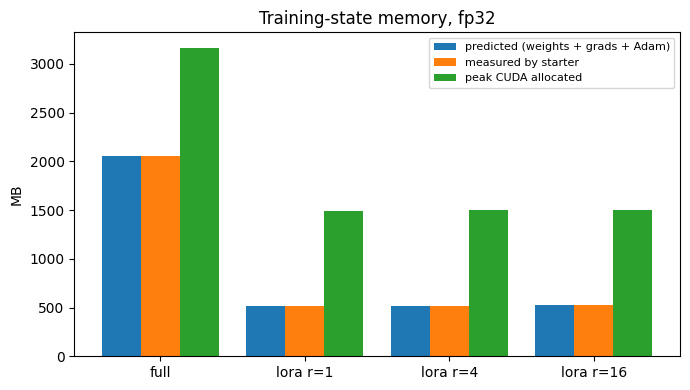

In [32]:
figure, axis = plt.subplots(figsize=(7, 4))
bar_positions = list(range(len(method_order)))
bar_width = 0.27
axis.bar([position - bar_width for position in bar_positions], to_mb(prediction_table.predicted_total), bar_width,
         label="predicted (weights + grads + Adam)")
axis.bar(bar_positions, to_mb(measured.measured_total), bar_width, label="measured by starter")
axis.bar([position + bar_width for position in bar_positions], to_mb(measured.peak_cuda_bytes), bar_width,
         label="peak CUDA allocated")
axis.set_xticks(bar_positions, method_order)
axis.set_ylabel("MB")
axis.set_title("Training-state memory, fp32")
axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig("figures/memory_by_method.png", dpi=150)
plt.show()

## Save the results

The README tables and the script version are built from this file, so I write every number above to `lab6_results.json`.

In [33]:
with open("lab6_results.json", "w") as results_file:
    json.dump(results, results_file, indent=1, default=float)
print("saved lab6_results.json")

saved lab6_results.json
